In [ ]:
import pandas as pd
import numpy as np
import re
from scipy import stats

# ── Load the 4 regional files ──────────────────────────────────────────────

files = {
    'AA1_708':     'Burgmaier_Genotype_Phenotype_Replication - AA1-708.csv',
    'AA709_1837':  'Burgmaier_Genotype_Phenotype_Replication - AA709-1837.csv',
    'AA1838_2624': 'Burgmaier_Genotype_Phenotype_Replication - AA1838-2624.csv',
    'AA2625_4074': 'Burgmaier_Genotype_Phenotype_Replication - AA2625-4074.csv',
}

def is_missense(variant):
    v = variant.strip()
    if not v.startswith('p.'):
        return False
    if any(x in v for x in ['*', 'fs', 'del', 'dup', 'ins', '?', 'ext', 'Ter']):
        return False
    return bool(re.match(r'p\.[A-Z][a-z]{2}\d+[A-Z][a-z]{2}$', v))

missense_variants = {}
for region, fname in files.items():
    df       = pd.read_csv(fname)
    variants = []
    for entry in df['Predicted protein change'].dropna():
        for v in entry.split(';'):
            if is_missense(v.strip()):
                variants.append(v.strip())
    missense_variants[region] = sorted(set(variants))

missense_AA1_708     = missense_variants['AA1_708']
missense_AA709_1837  = missense_variants['AA709_1837']
missense_AA1838_2624 = missense_variants['AA1838_2624']
missense_AA2625_4074 = missense_variants['AA2625_4074']

for region, vlist in missense_variants.items():
    print(f"{region}: {len(vlist)} unique missense variants")

# ── AA709-1837: with vs without p.Arg1624Trp ──────────────────────────────

df709 = pd.read_csv('Burgmaier_Genotype_Phenotype_Replication - AA709-1837.csv')

mask_r1642w = df709['Predicted protein change'].str.contains('Arg1624Trp', na=False)

print(f"\nAA709-1837 total: {len(df709)}")
print(f"Carrying p.Arg1624Trp: {mask_r1642w.sum()}")
print(f"Excluding p.Arg1624Trp: {(~mask_r1642w).sum()}")

# Functional class breakdown
print("\nFunctional class — with p.Arg1624Trp:")
print(df709[mask_r1642w]['Functional class'].value_counts().to_string())

print("\nFunctional class — without p.Arg1624Trp:")
print(df709[~mask_r1642w]['Functional class'].value_counts().to_string())

# Clinical outcomes comparison
def to_numeric(col):
    return pd.to_numeric(col, errors='coerce')

df709['krt_age']        = to_numeric(df709.iloc[:, 2])
df709['portal_htn_age'] = to_numeric(df709.iloc[:, 3])
df709['hepatic_age']    = to_numeric(df709.iloc[:, 4])
df709['had_krt']        = df709['krt_age'].notna().astype(int)
df709['had_portal_htn'] = df709['portal_htn_age'].notna().astype(int)
df709['had_hepatic']    = df709['hepatic_age'].notna().astype(int)

with_r    = df709[mask_r1642w]
without_r = df709[~mask_r1642w]

print("\n── Event rates: p.Arg1624Trp carriers vs non-carriers ──")
for event, label in [('had_krt',        'KRT'),
                     ('had_portal_htn', 'Portal HTN'),
                     ('had_hepatic',    'Hepatic')]:
    r_with    = with_r[event].mean()
    r_without = without_r[event].mean()
    a = with_r[event].values
    b = without_r[event].values
    table = [[sum(a==1), sum(a==0)], [sum(b==1), sum(b==0)]]
    OR, p = stats.fisher_exact(table)
    print(f"  {label:<15} carriers: {r_with:.3f}  non-carriers: {r_without:.3f}  OR={OR:.2f}  p={p:.4f}")

AA1_708: 19 unique missense variants
AA709_1837: 26 unique missense variants
AA1838_2624: 12 unique missense variants
AA2625_4074: 19 unique missense variants

AA709-1837 total: 51
Carrying p.Arg1624Trp: 12
Excluding p.Arg1624Trp: 39

Functional class — with p.Arg1624Trp:
Functional class
Null/ Mis709-1837           8
Mis709-1837/ Mis709-1837    4

Functional class — without p.Arg1624Trp:
Functional class
Null/ Mis709-1837           27
Mis709-1837/ Mis709-1837    12

── Event rates: p.Arg1624Trp carriers vs non-carriers ──
  KRT             carriers: 0.000  non-carriers: 0.103  OR=0.00  p=0.5612
  Portal HTN      carriers: 0.167  non-carriers: 0.385  OR=0.32  p=0.2934
  Hepatic         carriers: 0.000  non-carriers: 0.077  OR=0.00  p=1.0000


AA709-1837 original: n=51
AA709-1837 excl. p.Arg1624Trp: n=39

Original combined: 138 patients
region
AA1838_2624    22
AA1_708        44
AA2625_4074    21
AA709_1837     51

Excl. combined: 126 patients
region
AA1838_2624    22
AA1_708        44
AA2625_4074    21
AA709_excl     39

───────────────────────────────────────────────────────
ORIGINAL — KM_KRT
Overall log-rank: N=138, p = 0.013

Pairwise log-rank:
  AA2625–4074 vs AA1838–2624: p = 0.612
  AA1838–2624 vs AA1–708: p = 0.631
  AA1–708 vs AA709–1837: p < 0.001

At-risk counts:
  Region                                       0     5    10    15
  AA2625–4074                                 21    14    10     6
  AA1838–2624                                 22    13     7     2
  AA1–708                                     44    24    14     7
  AA709–1837                                  51    33    17     9
───────────────────────────────────────────────────────



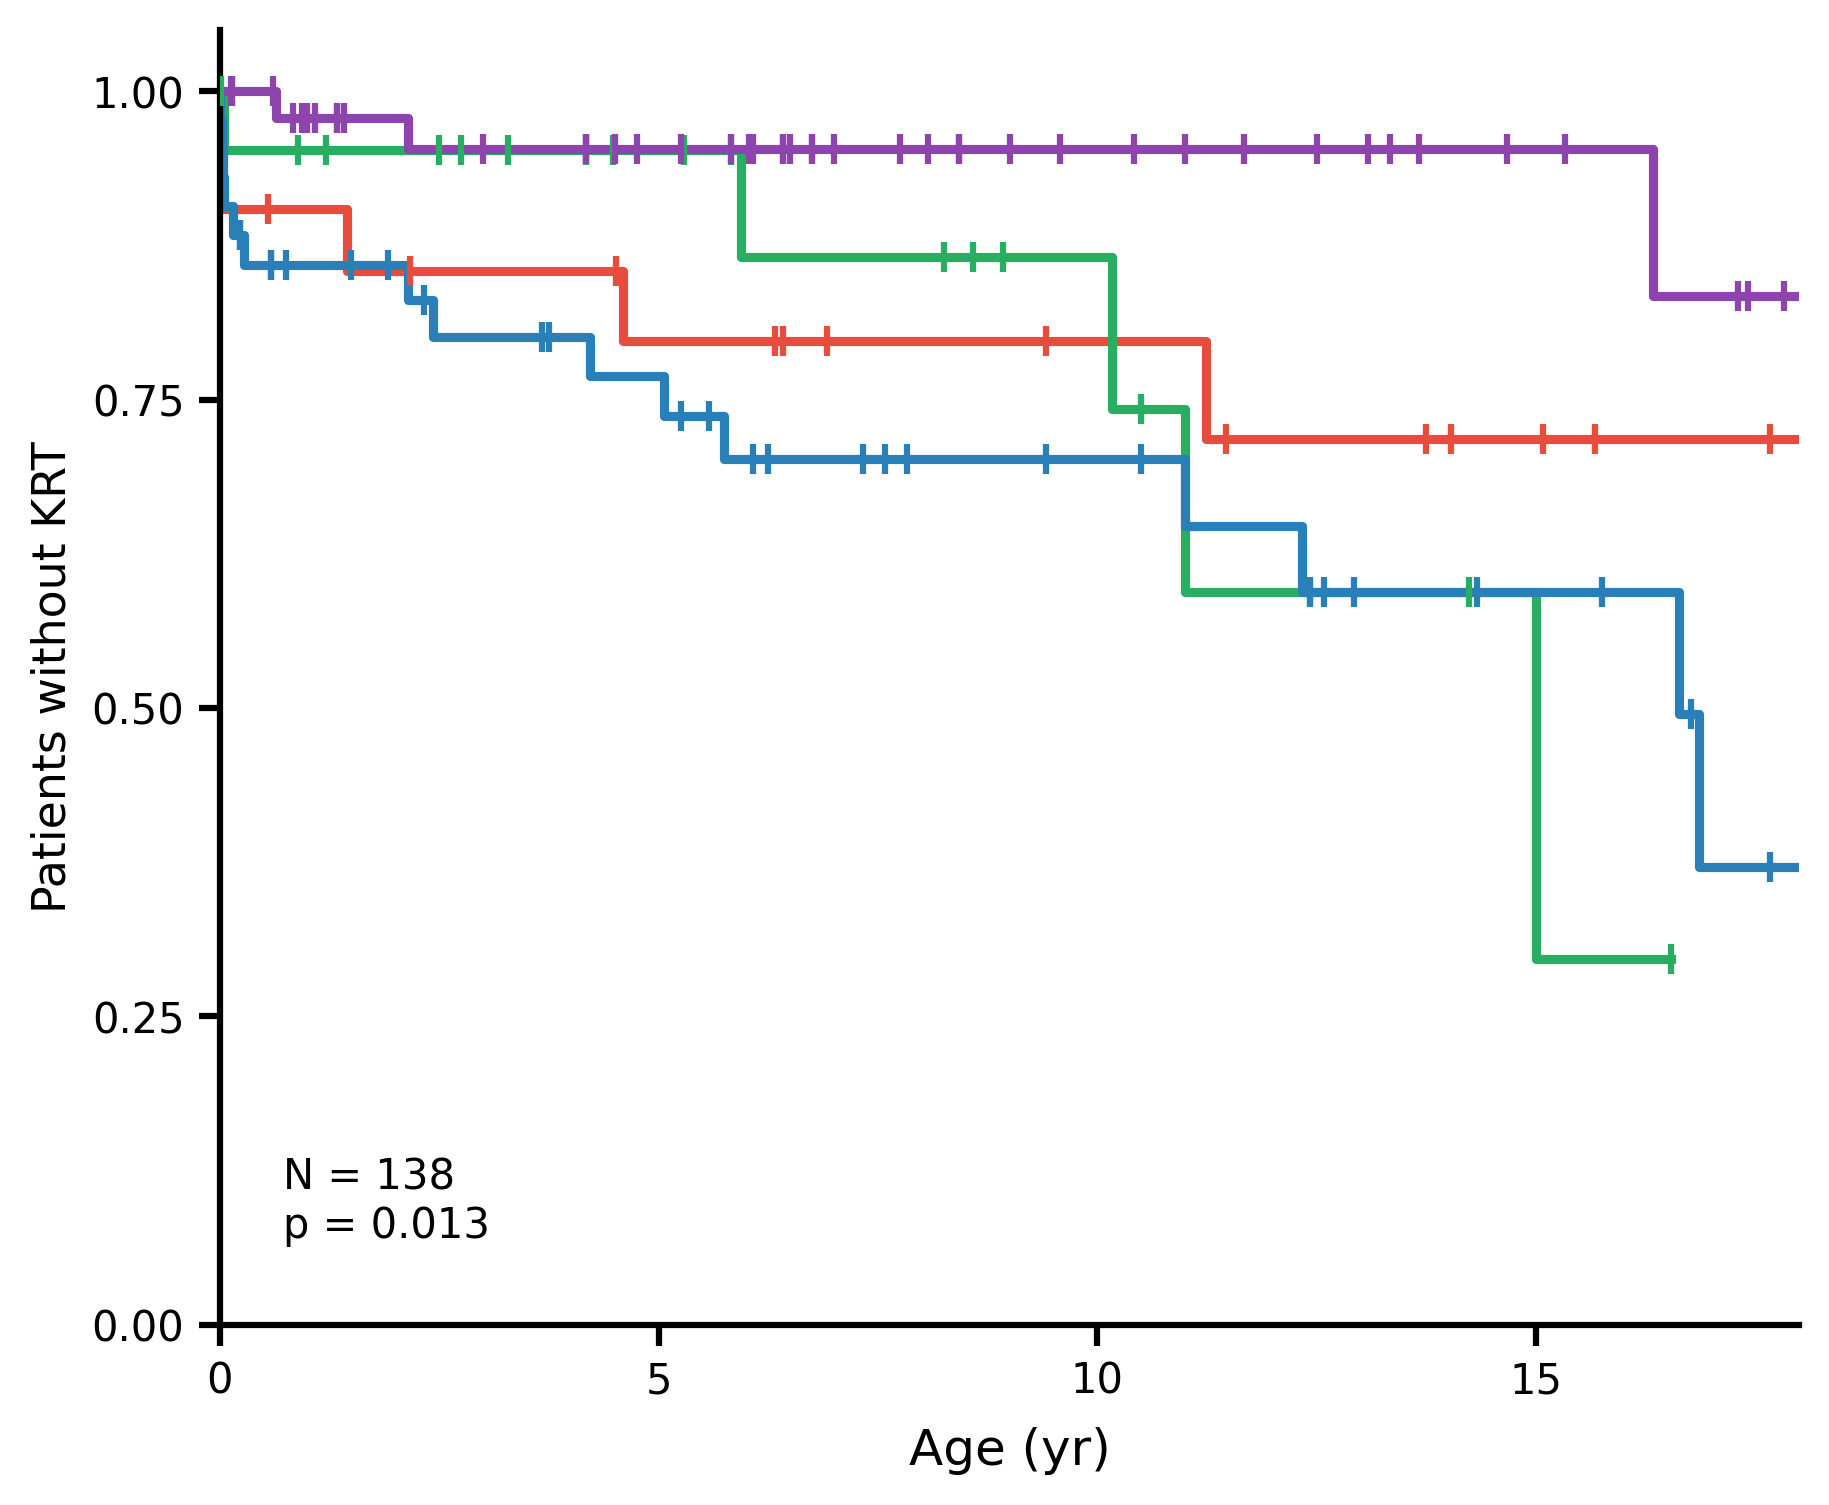

Saved: km_krt_original.png


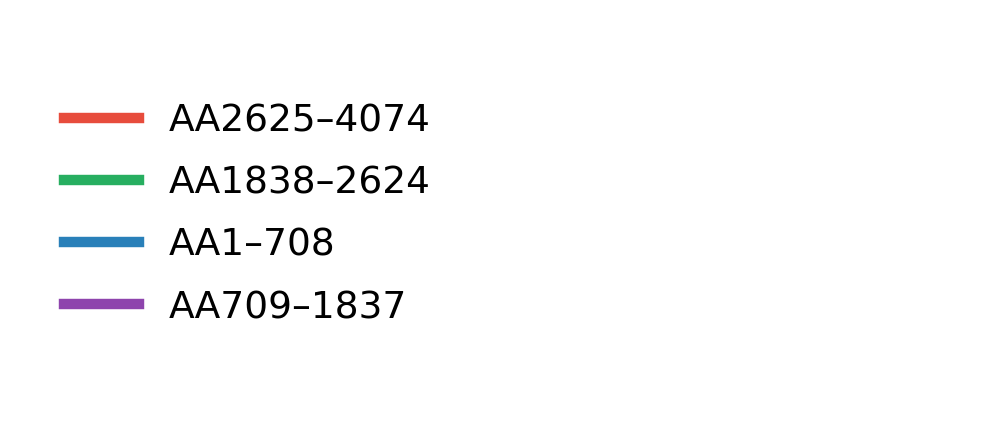

Saved: km_krt_original_legend.png

───────────────────────────────────────────────────────
ORIGINAL — KM_KRT
Overall log-rank: N=138, p = 0.013

Pairwise log-rank:
  AA2625–4074 vs AA1838–2624: p = 0.612
  AA1838–2624 vs AA1–708: p = 0.631
  AA1–708 vs AA709–1837: p < 0.001
───────────────────────────────────────────────────────


───────────────────────────────────────────────────────
ORIGINAL — KM_PORTAL_HTN
Overall log-rank: N=138, p = 0.003

Pairwise log-rank:
  AA2625–4074 vs AA1838–2624: p = 0.006
  AA1838–2624 vs AA1–708: p = 0.105
  AA1–708 vs AA709–1837: p = 0.237

At-risk counts:
  Region                                       0     5    10    15
  AA2625–4074                                 21    10     3     2
  AA1838–2624                                 22    12     7     2
  AA1–708                                     44    20    11     6
  AA709–1837                                  51    29    13     7
───────────────────────────────────────────────────────



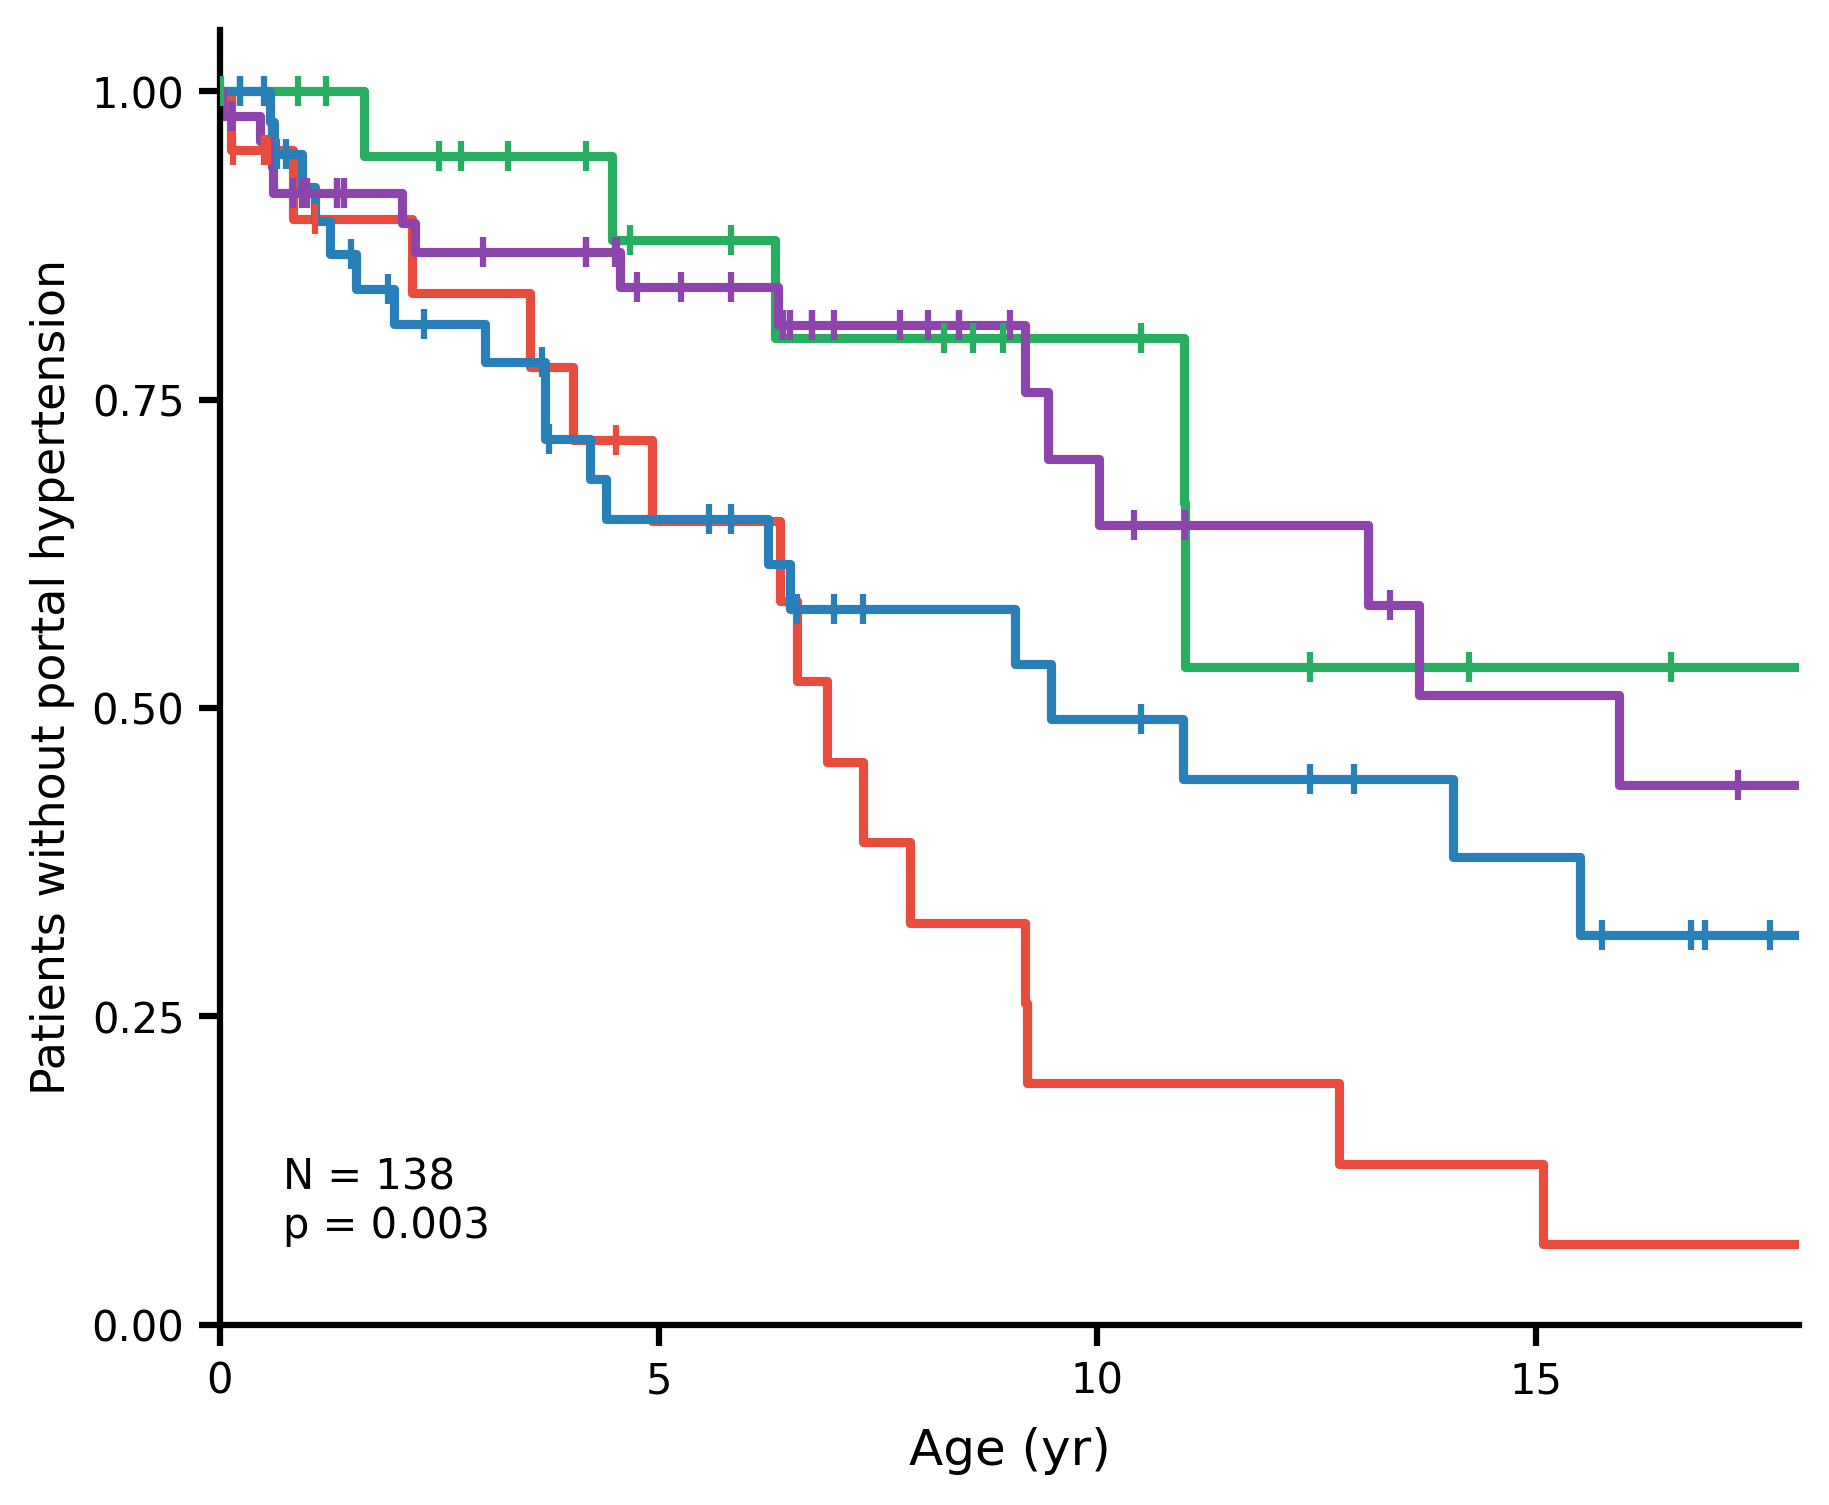

Saved: km_portal_htn_original.png


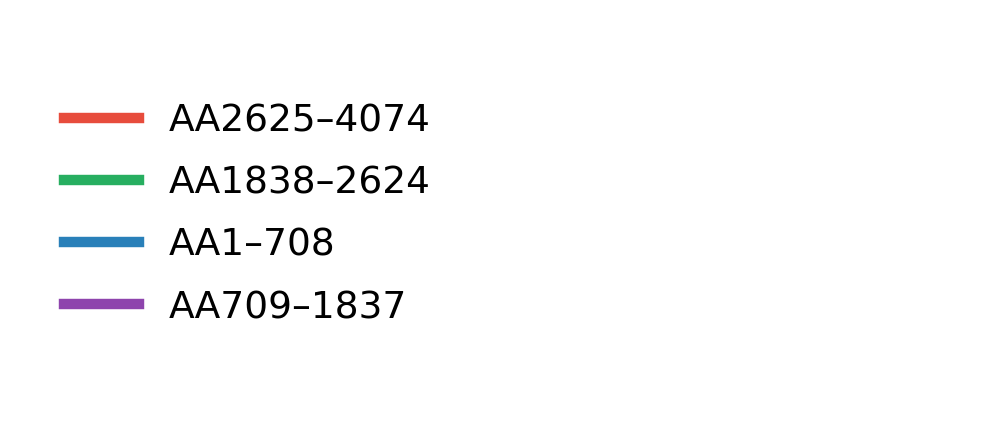

Saved: km_portal_htn_original_legend.png

───────────────────────────────────────────────────────
ORIGINAL — KM_PORTAL_HTN
Overall log-rank: N=138, p = 0.003

Pairwise log-rank:
  AA2625–4074 vs AA1838–2624: p = 0.006
  AA1838–2624 vs AA1–708: p = 0.105
  AA1–708 vs AA709–1837: p = 0.237
───────────────────────────────────────────────────────


───────────────────────────────────────────────────────
ORIGINAL — KM_HEPATIC
Overall log-rank: N=138, p < 0.001

Pairwise log-rank:
  AA2625–4074 vs AA1838–2624: p = 0.019
  AA1838–2624 vs AA1–708: p = 0.516
  AA1–708 vs AA709–1837: p = 0.549

At-risk counts:
  Region                                       0     5    10    15
  AA2625–4074                                 21    12     5     4
  AA1838–2624                                 22    13     8     3
  AA1–708                                     44    27    14     6
  AA709–1837                                  51    33    17     8
───────────────────────────────────────────────────────



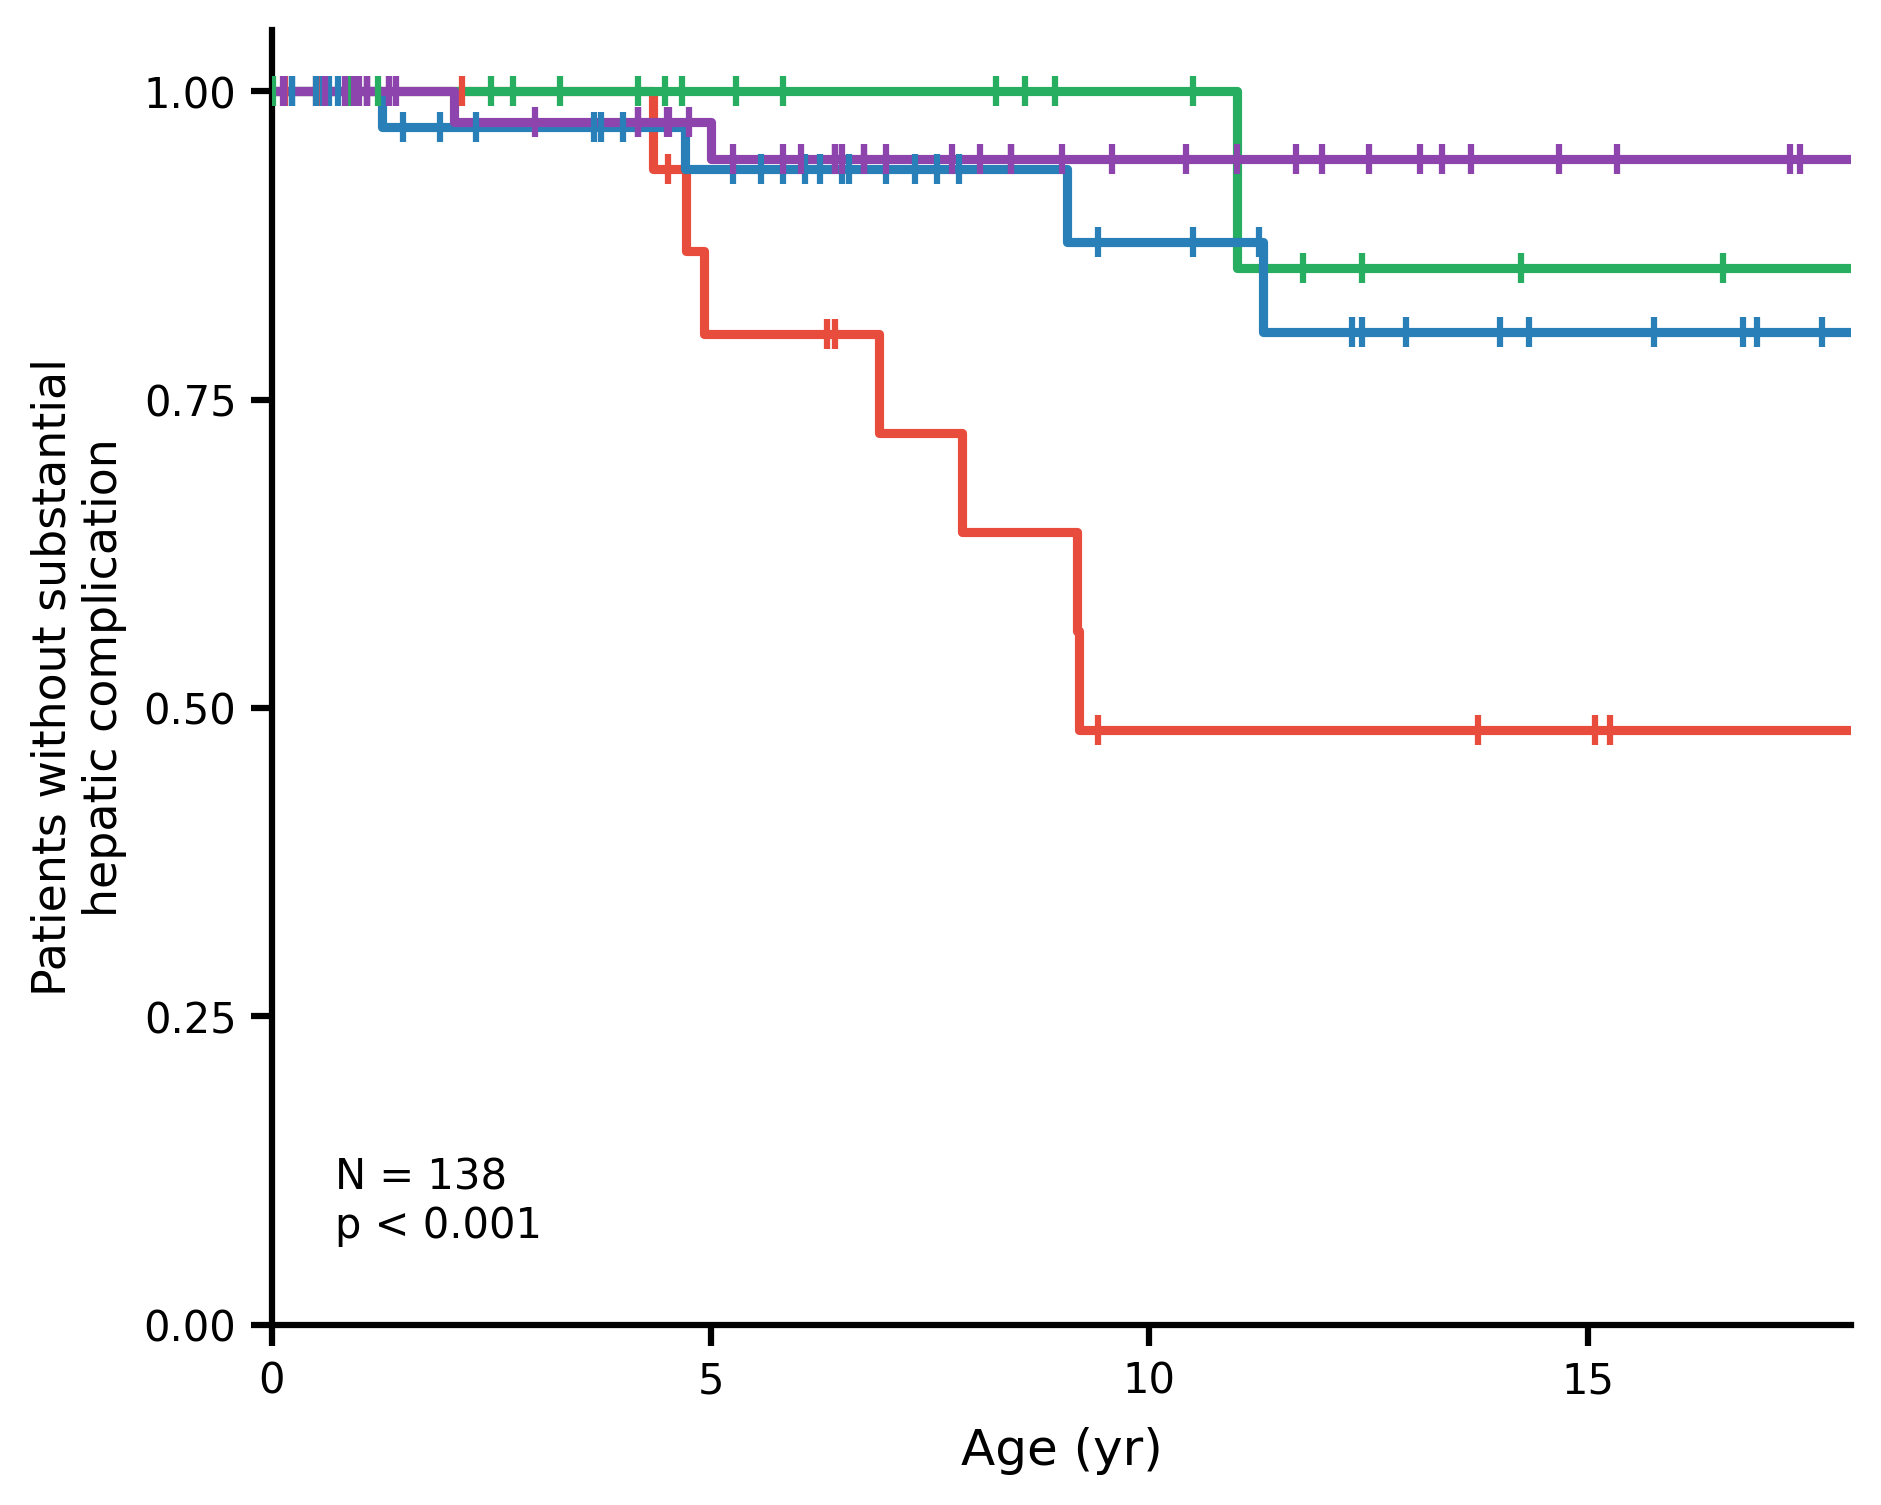

Saved: km_hepatic_original.png


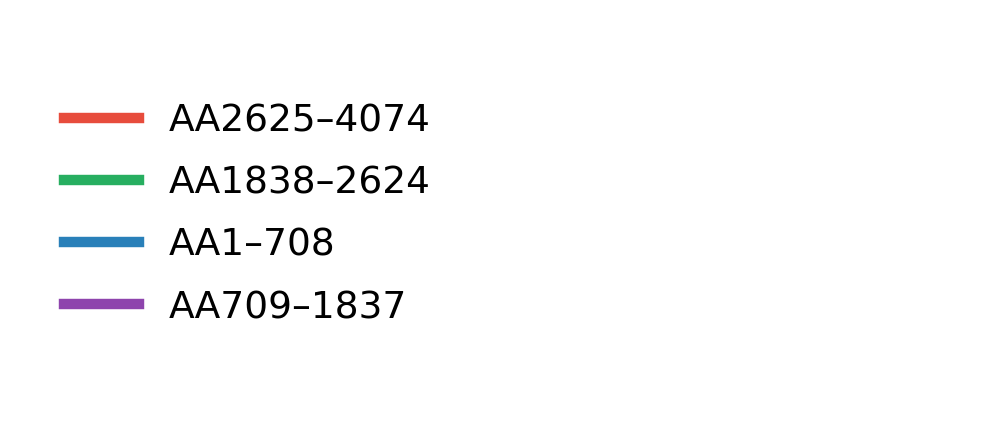

Saved: km_hepatic_original_legend.png

───────────────────────────────────────────────────────
ORIGINAL — KM_HEPATIC
Overall log-rank: N=138, p < 0.001

Pairwise log-rank:
  AA2625–4074 vs AA1838–2624: p = 0.019
  AA1838–2624 vs AA1–708: p = 0.516
  AA1–708 vs AA709–1837: p = 0.549
───────────────────────────────────────────────────────


───────────────────────────────────────────────────────
EXCL_R1642W — KM_KRT
Overall log-rank: N=126, p = 0.051

Pairwise log-rank:
  AA2625–4074 vs AA1838–2624: p = 0.612
  AA1838–2624 vs AA1–708: p = 0.631
  AA1–708 vs AA709–1837 (excl. p.Arg1624Trp): p = 0.005

At-risk counts:
  Region                                       0     5    10    15
  AA2625–4074                                 21    14    10     6
  AA1838–2624                                 22    13     7     2
  AA1–708                                     44    24    14     7
  AA709–1837 (excl. p.Arg1624Trp)             39    24    14     8
───────────────────────────────────────────

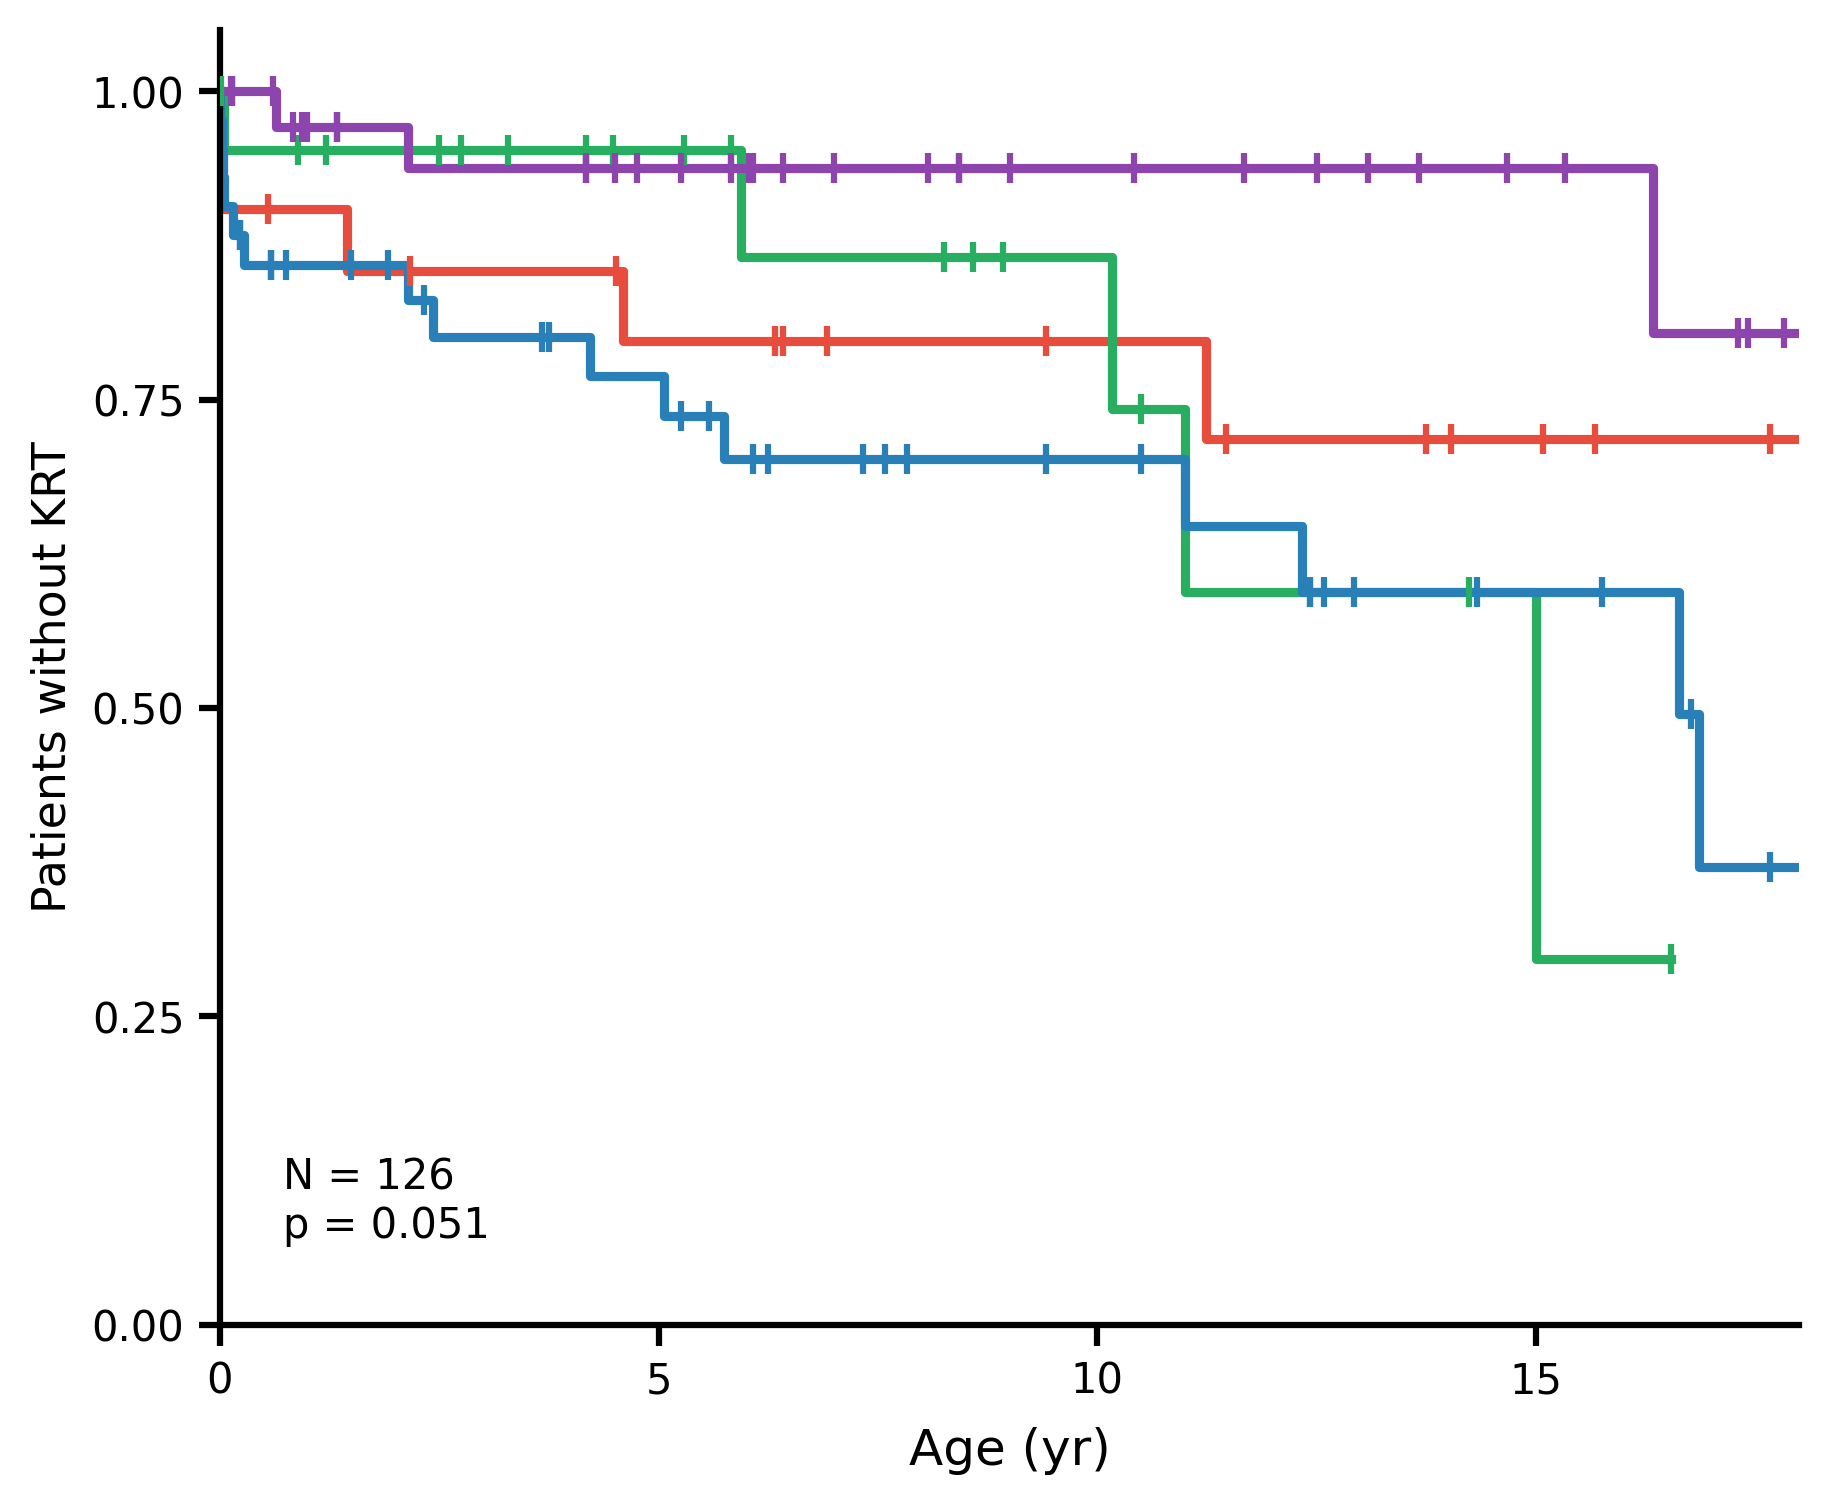

Saved: km_krt_excl_R1642W.png


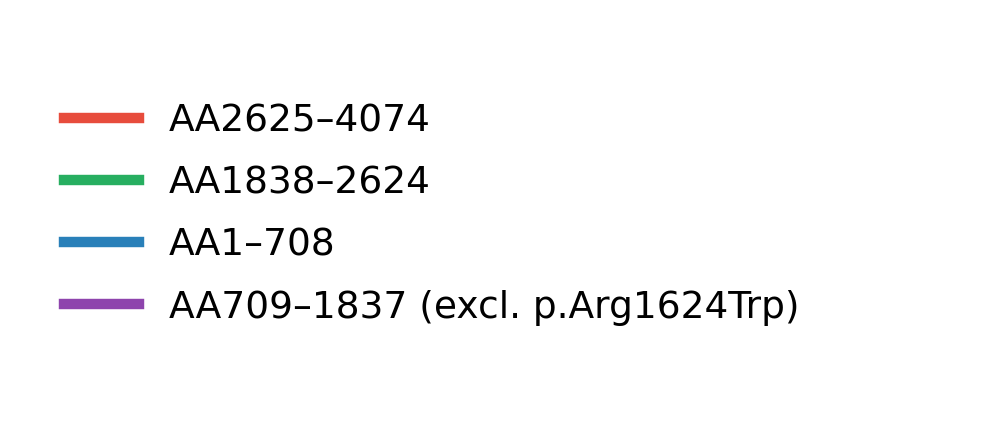

Saved: km_krt_excl_R1642W_legend.png

───────────────────────────────────────────────────────
EXCL_R1642W — KM_KRT
Overall log-rank: N=126, p = 0.051

Pairwise log-rank:
  AA2625–4074 vs AA1838–2624: p = 0.612
  AA1838–2624 vs AA1–708: p = 0.631
  AA1–708 vs AA709–1837 (excl. p.Arg1624Trp): p = 0.005
───────────────────────────────────────────────────────


───────────────────────────────────────────────────────
EXCL_R1642W — KM_PORTAL_HTN
Overall log-rank: N=126, p = 0.007

Pairwise log-rank:
  AA2625–4074 vs AA1838–2624: p = 0.006
  AA1838–2624 vs AA1–708: p = 0.105
  AA1–708 vs AA709–1837 (excl. p.Arg1624Trp): p = 0.401

At-risk counts:
  Region                                       0     5    10    15
  AA2625–4074                                 21    10     3     2
  AA1838–2624                                 22    12     7     2
  AA1–708                                     44    20    11     6
  AA709–1837 (excl. p.Arg1624Trp)             39    21    10     6
─────────────────

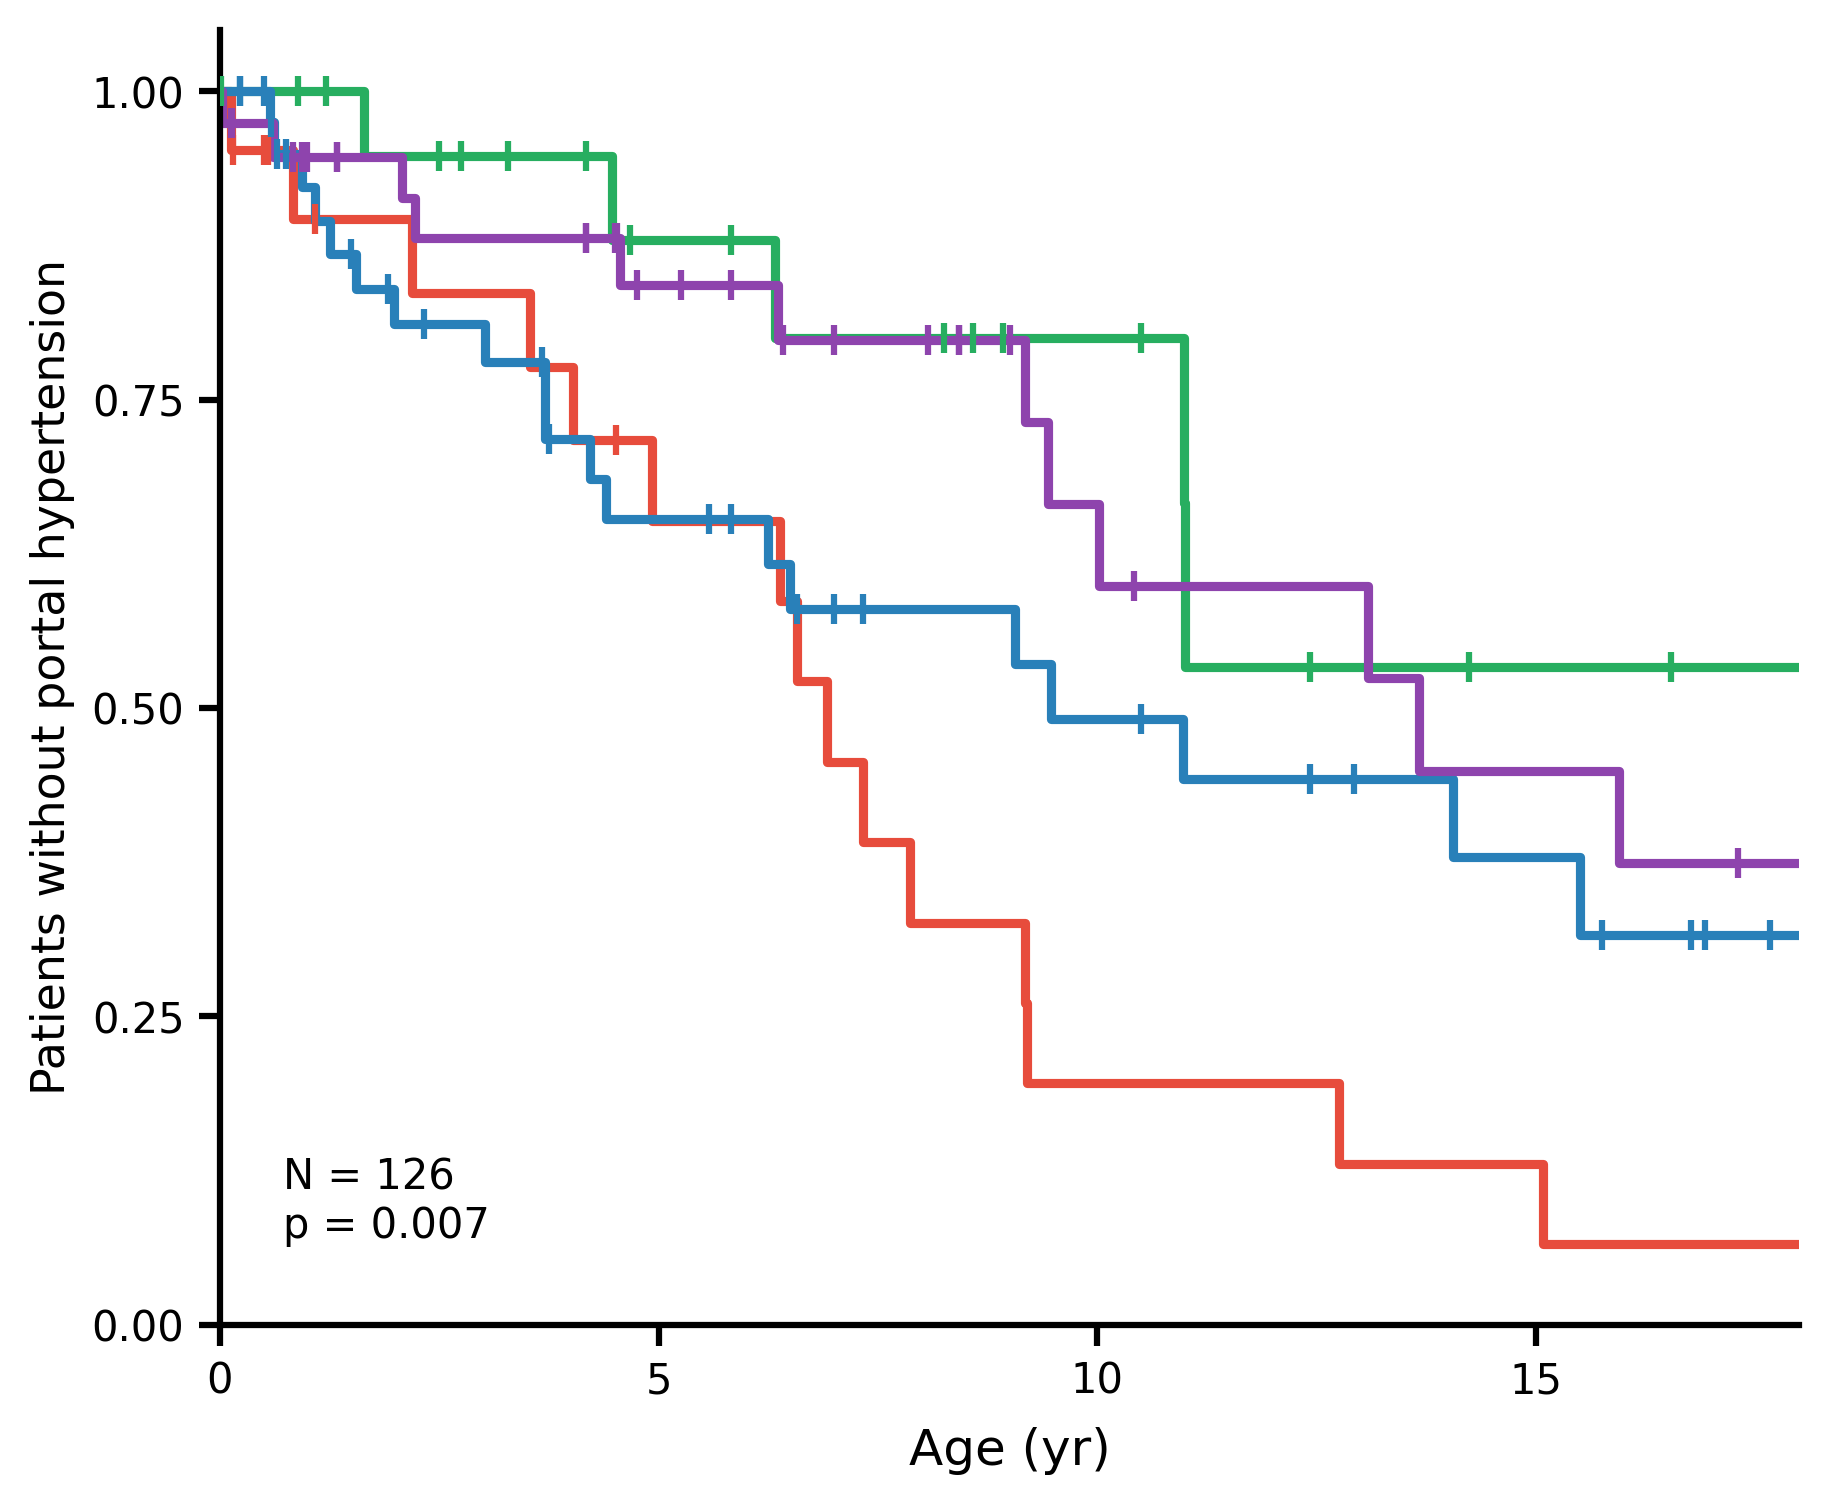

Saved: km_portal_htn_excl_R1642W.png


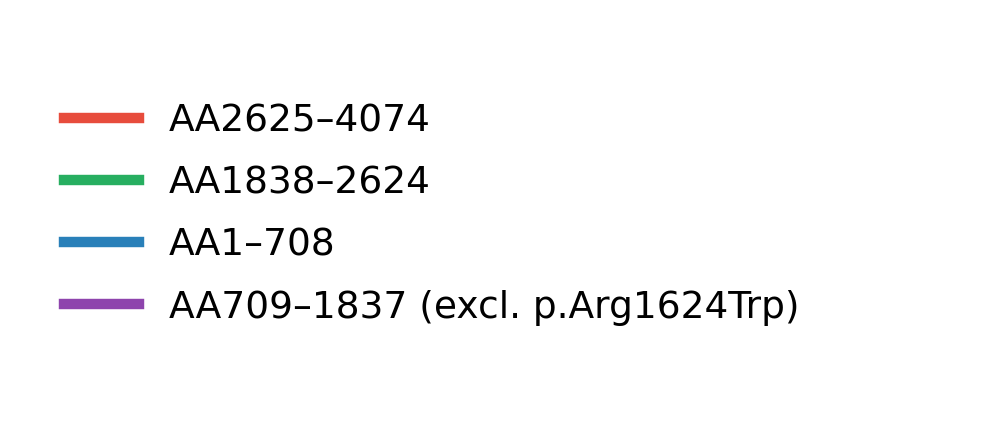

Saved: km_portal_htn_excl_R1642W_legend.png

───────────────────────────────────────────────────────
EXCL_R1642W — KM_PORTAL_HTN
Overall log-rank: N=126, p = 0.007

Pairwise log-rank:
  AA2625–4074 vs AA1838–2624: p = 0.006
  AA1838–2624 vs AA1–708: p = 0.105
  AA1–708 vs AA709–1837 (excl. p.Arg1624Trp): p = 0.401
───────────────────────────────────────────────────────


───────────────────────────────────────────────────────
EXCL_R1642W — KM_HEPATIC
Overall log-rank: N=126, p = 0.003

Pairwise log-rank:
  AA2625–4074 vs AA1838–2624: p = 0.019
  AA1838–2624 vs AA1–708: p = 0.516
  AA1–708 vs AA709–1837 (excl. p.Arg1624Trp): p = 0.768

At-risk counts:
  Region                                       0     5    10    15
  AA2625–4074                                 21    12     5     4
  AA1838–2624                                 22    13     8     3
  AA1–708                                     44    27    14     6
  AA709–1837 (excl. p.Arg1624Trp)             39    24    14     7
──────

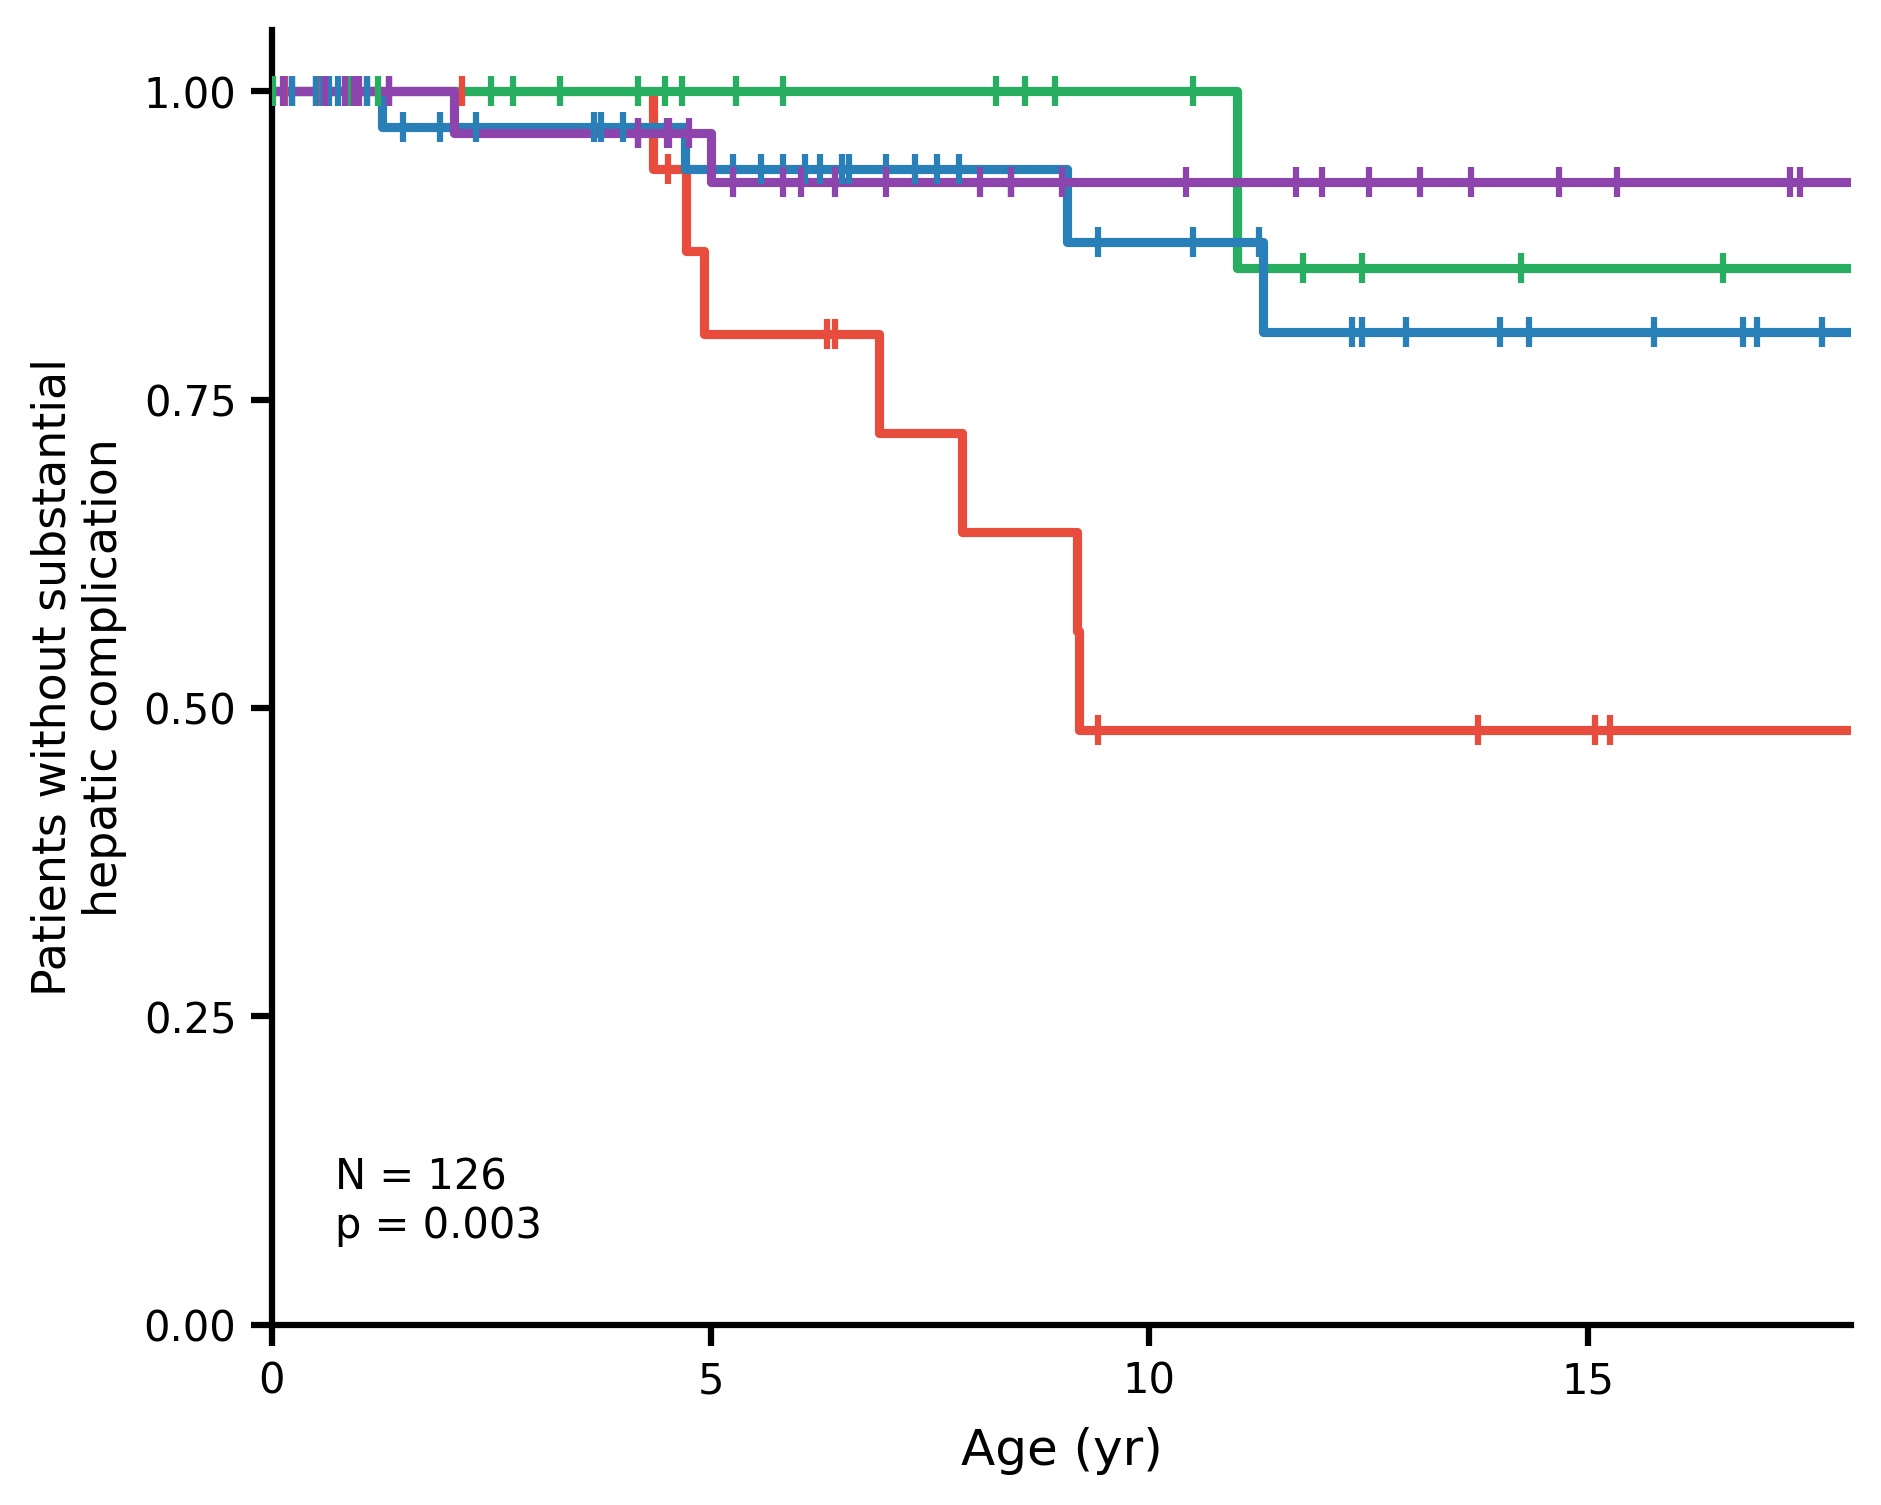

Saved: km_hepatic_excl_R1642W.png


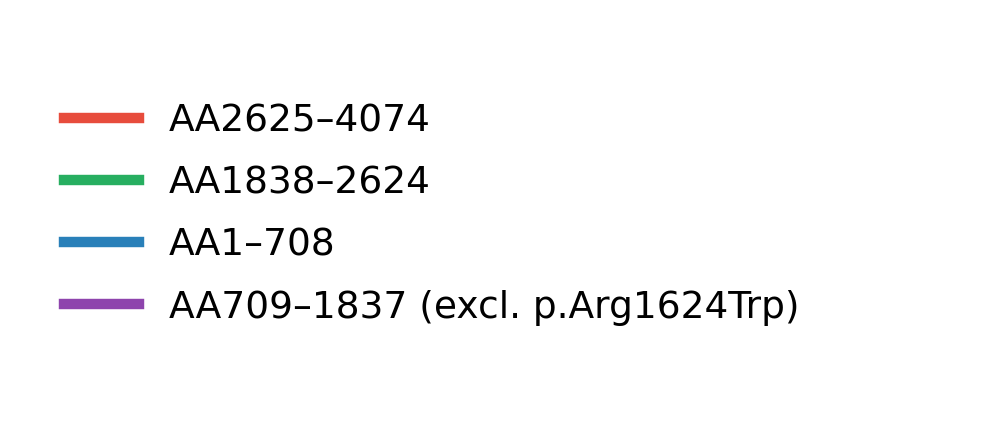

Saved: km_hepatic_excl_R1642W_legend.png

───────────────────────────────────────────────────────
EXCL_R1642W — KM_HEPATIC
Overall log-rank: N=126, p = 0.003

Pairwise log-rank:
  AA2625–4074 vs AA1838–2624: p = 0.019
  AA1838–2624 vs AA1–708: p = 0.516
  AA1–708 vs AA709–1837 (excl. p.Arg1624Trp): p = 0.768
───────────────────────────────────────────────────────



In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test, multivariate_logrank_test

plt.rcParams.update({
    'font.family':       'DejaVu Sans',
    'font.size':         11,
    'axes.linewidth':    1.5,
    'axes.spines.top':   False,
    'axes.spines.right': False,
    'xtick.major.width': 1.5,
    'ytick.major.width': 1.5,
    'xtick.major.size':  5,
    'ytick.major.size':  5,
    'figure.dpi':        300,
    'figure.facecolor':  'none',
    'axes.facecolor':    'none',
})

def to_numeric(col):
    return pd.to_numeric(col, errors='coerce')

def prepare_survival(df, event_col, age_col, followup_col='followup_age'):
    duration = np.where(df[event_col] == 1, df[age_col], df[followup_col])
    duration = np.where((duration <= 0) & (df[event_col].values == 0),
                        np.nan, duration)
    duration = np.where(duration <= 0, 0.001, duration)
    mask     = ~np.isnan(duration)
    return duration[mask].astype(float), df[event_col].values[mask].astype(int)

def fmt_p(p):
    if p < 0.001: return 'p < 0.001'
    return f'p = {p:.3f}'

# ── Load and parse all 4 regional files ───────────────────────────────────

regional_files = {
    'AA1_708':     'Burgmaier_Genotype_Phenotype_Replication - AA1-708.csv',
    'AA709_1837':  'Burgmaier_Genotype_Phenotype_Replication - AA709-1837.csv',
    'AA1838_2624': 'Burgmaier_Genotype_Phenotype_Replication - AA1838-2624.csv',
    'AA2625_4074': 'Burgmaier_Genotype_Phenotype_Replication - AA2625-4074.csv',
}

cols = ['region', 'had_krt', 'had_portal_htn', 'had_hepatic',
        'krt_age', 'portal_htn_age', 'hepatic_age', 'followup_age']

def parse_regional(df, region):
    df = df.copy()
    df['region']         = region
    df['krt_age']        = to_numeric(df.iloc[:, 2])
    df['portal_htn_age'] = to_numeric(df.iloc[:, 3])
    df['hepatic_age']    = to_numeric(df.iloc[:, 4])
    df['followup_age']   = to_numeric(
        df.iloc[:, 5].astype(str).str.extract(r'([\d.]+)')[0])
    df['had_krt']        = df['krt_age'].notna().astype(int)
    df['had_portal_htn'] = df['portal_htn_age'].notna().astype(int)
    df['had_hepatic']    = df['hepatic_age'].notna().astype(int)
    return df

parsed = {}
for region, fname in regional_files.items():
    parsed[region] = parse_regional(pd.read_csv(fname), region)

# ── Build the two versions of AA709-1837 ──────────────────────────────────

df709       = parsed['AA709_1837'].copy()
mask_r1642w = pd.read_csv(regional_files['AA709_1837'])[
    'Predicted protein change'].str.contains('Arg1624Trp', na=False)

df709_excl          = df709[~mask_r1642w.values].copy()
df709_excl['region'] = 'AA709_excl'

print(f"AA709-1837 original: n={len(df709)}")
print(f"AA709-1837 excl. p.Arg1624Trp: n={len(df709_excl)}")

# ── Two combined datasets ─────────────────────────────────────────────────

# Version 1: original 4 groups
combined_orig = pd.concat([df[cols] for df in parsed.values()], ignore_index=True)

# Version 2: AA709_1837 replaced by excl. version
combined_excl = pd.concat([
    parsed['AA1_708'][cols],
    parsed['AA1838_2624'][cols],
    parsed['AA2625_4074'][cols],
    df709_excl[cols],
], ignore_index=True)

print(f"\nOriginal combined: {len(combined_orig)} patients")
print(combined_orig.groupby('region').size().to_string())
print(f"\nExcl. combined: {len(combined_excl)} patients")
print(combined_excl.groupby('region').size().to_string())

# ── Ladder, labels, colors ────────────────────────────────────────────────

versions = {
    'original': {
        'data':   combined_orig,
        'ladder': ['AA2625_4074', 'AA1838_2624', 'AA1_708', 'AA709_1837'],
        'labels': ['AA2625–4074', 'AA1838–2624', 'AA1–708', 'AA709–1837'],
        'colors': ['#e74c3c', '#27ae60', '#2980b9', '#8e44ad'],
    },
    'excl_R1642W': {
        'data':   combined_excl,
        'ladder': ['AA2625_4074', 'AA1838_2624', 'AA1_708', 'AA709_excl'],
        'labels': ['AA2625–4074', 'AA1838–2624', 'AA1–708',
                   'AA709–1837 (excl. p.Arg1624Trp)'],
        'colors': ['#e74c3c', '#27ae60', '#2980b9', '#8e44ad'],
    },
}

km_pairs = [
    ('AA2625_4074', 'AA1838_2624', 'AA2625–4074 vs AA1838–2624'),
    ('AA1838_2624', 'AA1_708',     'AA1838–2624 vs AA1–708'),
]

endpoints = [
    ('had_krt',        'krt_age',
     'Patients without KRT',
     'km_krt'),
    ('had_portal_htn', 'portal_htn_age',
     'Patients without portal hypertension',
     'km_portal_htn'),
    ('had_hepatic',    'hepatic_age',
     'Patients without substantial\nhepatic complication',
     'km_hepatic'),
]

timepoints = [0, 5, 10, 15]

# ── Plot ──────────────────────────────────────────────────────────────────

for version_name, version in versions.items():
    data_v  = version['data']
    ladder  = version['ladder']
    labels  = version['labels']
    colors  = version['colors']

    # Pairwise pairs — use correct AA709 key for this version
    aa709_key = 'AA709_1837' if version_name == 'original' else 'AA709_excl'
    aa709_lbl = 'AA709–1837' if version_name == 'original' else 'AA709–1837 (excl. p.Arg1624Trp)'
    pairs = km_pairs + [
        ('AA1_708', aa709_key, f'AA1–708 vs {aa709_lbl}'),
    ]

    for (event_col, age_col, ylabel, fname_base) in endpoints:

        fig, ax = plt.subplots(figsize=(6.5, 5.2))
        fig.patch.set_alpha(0)
        ax.patch.set_alpha(0)
        fig.subplots_adjust(left=0.16, right=0.97, top=0.96, bottom=0.13)

        n_total = 0
        for region, label, color in zip(ladder, labels, colors):
            subset   = data_v[data_v['region'] == region].copy()
            n_total += len(subset)
            duration, event = prepare_survival(subset, event_col, age_col)
            kmf = KaplanMeierFitter()
            kmf.fit(duration, event_observed=event)
            kmf.plot_survival_function(
                ax=ax, ci_show=False, color=color,
                linewidth=2.2, label=label,
            )
            censored_times = duration[event == 0]
            if len(censored_times) > 0:
                censored_probs = kmf.survival_function_at_times(censored_times).values
                ax.scatter(censored_times, censored_probs,
                           marker='|', color=color, s=50,
                           linewidth=1.5, zorder=5)

        # Overall log-rank
        durations_all, events_all, groups_all = [], [], []
        for region in ladder:
            subset = data_v[data_v['region'] == region].copy()
            d, e   = prepare_survival(subset, event_col, age_col)
            durations_all.extend(d)
            events_all.extend(e)
            groups_all.extend([region] * len(d))
        result = multivariate_logrank_test(durations_all, groups_all, events_all)

        ax.text(0.04, 0.06,
                f'N = {n_total}\n{fmt_p(result.p_value)}',
                transform=ax.transAxes, fontsize=10, va='bottom')

# ── Print stats ───────────────────────────────────────────────────
        print(f'\n{"─"*55}')
        print(f'{version_name.upper()} — {fname_base.upper()}')
        print(f'Overall log-rank: N={n_total}, {fmt_p(result.p_value)}')
        print('\nPairwise log-rank:')
        for r1, r2, plabel in pairs:
            s1 = data_v[data_v['region'] == r1]
            s2 = data_v[data_v['region'] == r2]
            d1, e1 = prepare_survival(s1, event_col, age_col)
            d2, e2 = prepare_survival(s2, event_col, age_col)
            lr = logrank_test(d1, d2, e1, e2)
            print(f'  {plabel}: {fmt_p(lr.p_value)}')

        print('\nAt-risk counts:')
        header = f"  {'Region':<40}" + ''.join(f'{t:>6}' for t in timepoints)
        print(header)
        for region, label in zip(ladder, labels):
            subset   = data_v[data_v['region'] == region].copy()
            n_r      = len(subset)
            duration, event = prepare_survival(subset, event_col, age_col)
            counts   = [n_r if t == 0 else int(np.sum(duration >= t))
                        for t in timepoints]
            print(f"  {label:<40}" + ''.join(f'{c:>6}' for c in counts))
        print(f'{"─"*55}\n')
        leg = ax.get_legend()
        if leg: leg.remove()

        ax.set_xlim(0, 18)
        ax.set_ylim(0, 1.05)
        ax.set_xlabel('Age (yr)', fontsize=12, labelpad=6)
        ax.set_ylabel(ylabel, fontsize=11)
        ax.set_xticks([0, 5, 10, 15])
        ax.set_yticks([0.00, 0.25, 0.50, 0.75, 1.00])
        ax.yaxis.set_major_formatter(
            ticker.FuncFormatter(lambda x, _: f'{x:.2f}'))
        ax.tick_params(axis='both', labelsize=10)

        fname = f'{fname_base}_{version_name}.png'
        plt.savefig(fname, dpi=300, bbox_inches='tight', transparent=True)
        plt.show()
        print(f'Saved: {fname}')

        # ── Legend PNG ────────────────────────────────────────────────────
        fig_leg, ax_leg = plt.subplots(figsize=(4.0, 1.6))
        fig_leg.patch.set_alpha(0)
        ax_leg.patch.set_alpha(0)
        ax_leg.axis('off')
        handles = [plt.Line2D([0], [0], color=c, linewidth=2.5) for c in colors]
        ax_leg.legend(handles, labels, loc='center left',
                      fontsize=9, frameon=False,
                      handlelength=2.0, labelspacing=0.7)
        plt.savefig(f'{fname_base}_{version_name}_legend.png', dpi=300,
                    bbox_inches='tight', transparent=True)
        plt.show()
        print(f'Saved: {fname_base}_{version_name}_legend.png')

        # ── Print stats ───────────────────────────────────────────────────
        print(f'\n{"─"*55}')
        print(f'{version_name.upper()} — {fname_base.upper()}')
        print(f'Overall log-rank: N={n_total}, {fmt_p(result.p_value)}')
        print('\nPairwise log-rank:')
        for r1, r2, plabel in pairs:
            s1 = data_v[data_v['region'] == r1]
            s2 = data_v[data_v['region'] == r2]
            d1, e1 = prepare_survival(s1, event_col, age_col)
            d2, e2 = prepare_survival(s2, event_col, age_col)
            lr = logrank_test(d1, d2, e1, e2)
            print(f'  {plabel}: {fmt_p(lr.p_value)}')
        print(f'{"─"*55}\n')

In [ ]:
# ── Pairwise log-rank: KRT, all combinations, both versions ───────────────

from itertools import combinations

for version_name, version in versions.items():
    data_v  = version['data']
    ladder  = version['ladder']
    labels  = version['labels']

    print(f'\n{"─"*60}')
    print(f'ALL PAIRWISE LOG-RANK — KRT — {version_name.upper()}')
    print(f'{"─"*60}')
    print(f'  {"Comparison":<50} p-value')
    print(f'  {"─"*50}')

    for (r1, r2) in combinations(ladder, 2):
        s1 = data_v[data_v['region'] == r1]
        s2 = data_v[data_v['region'] == r2]
        d1, e1 = prepare_survival(s1, 'had_krt', 'krt_age')
        d2, e2 = prepare_survival(s2, 'had_krt', 'krt_age')
        lr     = logrank_test(d1, d2, e1, e2)

        l1 = labels[ladder.index(r1)]
        l2 = labels[ladder.index(r2)]
        sig = ' *' if lr.p_value < 0.05 else ''
        print(f'  {l1} vs {l2:<30} {fmt_p(lr.p_value)}{sig}')

    print(f'{"─"*60}')


────────────────────────────────────────────────────────────
ALL PAIRWISE LOG-RANK — KRT — ORIGINAL
────────────────────────────────────────────────────────────
  Comparison                                         p-value
  ──────────────────────────────────────────────────
  AA2625–4074 vs AA1838–2624                    p = 0.612
  AA2625–4074 vs AA1–708                        p = 0.348
  AA2625–4074 vs AA709–1837                     p = 0.081
  AA1838–2624 vs AA1–708                        p = 0.631
  AA1838–2624 vs AA709–1837                     p = 0.013 *
  AA1–708 vs AA709–1837                     p < 0.001 *
────────────────────────────────────────────────────────────

────────────────────────────────────────────────────────────
ALL PAIRWISE LOG-RANK — KRT — EXCL_R1642W
────────────────────────────────────────────────────────────
  Comparison                                         p-value
  ──────────────────────────────────────────────────
  AA2625–4074 vs AA1838–2624        